# Linear Baseline: OLS and Elastic Net

In this notebook, we establish the baseline regression models for predicting Remaining Useful Life (RUL):
1. **Ordinary Least Squares (OLS)** fitted on raw operating settings and sensor readings (V1: 24 features).
2. **Elastic Net** fitted on rolling mean, standard deviation, and trend slope features alongside current readings (V2: 57 features).

Evaluation is performed using an engine-level split and 100 fixed validation cutoff points to mirror operational testing.

In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import ElasticNet, LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from load_data import ALL_SENSORS, SETTINGS, load_test, load_train
from features import FEATURES, add_rolling_features
from evaluation import VAL_ENGINES, mae, rmse, split_train_val, test_points, validation_points

## 1. Data

Load the training and test sets, compute rolling features, split the training engines into train (80 engines) and validation (20 engines), and extract the 100 fixed validation cutoff points and test points.

In [2]:
train = add_rolling_features(load_train())
test = add_rolling_features(load_test())
train_df, val_df = split_train_val(train)
val_pts = validation_points(val_df)
test_pts = test_points(test)

print(f"train_df: {len(train_df)} rows, {train_df['engine_id'].nunique()} engines")
print(f"val_df: {len(val_df)} rows, {val_df['engine_id'].nunique()} engines")
print(f"val_pts: {len(val_pts)} rows, test_pts: {len(test_pts)} rows")
print(f"VAL_ENGINES: {VAL_ENGINES}")

train_df: 16390 rows, 80 engines
val_df: 4241 rows, 20 engines
val_pts: 100 rows, test_pts: 100 rows
VAL_ENGINES: [np.int64(8), np.int64(9), np.int64(13), np.int64(18), np.int64(37), np.int64(46), np.int64(48), np.int64(50), np.int64(55), np.int64(62), np.int64(64), np.int64(69), np.int64(72), np.int64(74), np.int64(76), np.int64(84), np.int64(85), np.int64(87), np.int64(90), np.int64(95)]


## 2. Two Feature Sets

- **V1 (Raw):** 3 operational settings + 21 sensors = 24 raw columns (current cycle only).
- **V2 (Engineered):** Cycle, 14 active sensors, and 10-cycle rolling mean, std, and slope = 57 columns.

In [3]:
V1 = SETTINGS + ALL_SENSORS
V2 = FEATURES

print(f"V1 count: {len(V1)}")
print(f"V1 features: {V1}\n")
print(f"V2 count: {len(V2)}")
print(f"V2 features (first 6): {V2[:6]}")
print(f"V2 features (last 3): {V2[-3:]}")

V1 count: 24
V1 features: ['setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']

V2 count: 57
V2 features (first 6): ['cycle', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8']
V2 features (last 3): ['sensor_21_mean', 'sensor_21_std', 'sensor_21_slope']


## 3. Two Models, Fixed Settings

We construct pipelines with `StandardScaler` followed by the regression estimator, ensuring the scaler is fitted solely on the training engine rows (`train_df`).
- **OLS on V1:** Standardized OLS linear regression on the 24 raw features.
- **Elastic Net on V2:** Standardized Elastic Net (`alpha=1`, `l1_ratio=0.5`, `max_iter=50_000`, `random_state=42`) on the 57 engineered features.

In [4]:
ols = make_pipeline(StandardScaler(), LinearRegression())
ols.fit(train_df[V1], train_df["rul"])

en = make_pipeline(
    StandardScaler(),
    ElasticNet(alpha=1, l1_ratio=0.5, max_iter=50_000, random_state=42),
)
en.fit(train_df[V2], train_df["rul"])

print("Successfully fitted OLS on V1 and Elastic Net on V2.")

Successfully fitted OLS on V1 and Elastic Net on V2.


## 4. Validation Scores

Evaluate both models at the 100 fixed validation cutoff points (`val_pts`), reporting Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

In [5]:
ols_val_pred = ols.predict(val_pts[V1])
en_val_pred = en.predict(val_pts[V2])
y_val = val_pts["rul"].values

val_scores = pd.DataFrame([
    {
        "Model": "OLS",
        "Features": "V1 (24 raw)",
        "MAE": mae(y_val, ols_val_pred),
        "RMSE": rmse(y_val, ols_val_pred),
    },
    {
        "Model": "Elastic Net",
        "Features": "V2 (57 rolling)",
        "MAE": mae(y_val, en_val_pred),
        "RMSE": rmse(y_val, en_val_pred),
    },
])

val_scores.round(2)

,Model,Features,MAE,RMSE
0,OLS,V1 (24 raw),32.86,42.92
1,Elastic Net,V2 (57 rolling),31.66,41.77


## 5. Underfitting Check

Compare the RMSE on all `train_df` rows against all `val_df` rows for both models.

In [6]:
ols_train_pred = ols.predict(train_df[V1])
en_train_pred = en.predict(train_df[V2])
ols_all_val_pred = ols.predict(val_df[V1])
en_all_val_pred = en.predict(val_df[V2])

underfit_scores = pd.DataFrame([
    {
        "Model": "OLS (V1)",
        "Train RMSE (all rows)": rmse(train_df["rul"], ols_train_pred),
        "Val RMSE (all rows)": rmse(val_df["rul"], ols_all_val_pred),
    },
    {
        "Model": "Elastic Net (V2)",
        "Train RMSE (all rows)": rmse(train_df["rul"], en_train_pred),
        "Val RMSE (all rows)": rmse(val_df["rul"], en_all_val_pred),
    },
])

underfit_scores.round(2)

,Model,Train RMSE (all rows),Val RMSE (all rows)
0,OLS (V1),43.31,49.72
1,Elastic Net (V2),39.30,47.25


The training error is high too, so the linear model mostly underfits (high bias).

## 6. Diagnostics for Elastic Net

Inspect the residuals ($y - \hat{y}$) and check model assumptions on the 100 validation points with a 2×2 diagnostic panel:
1. Predicted vs. actual RUL (with identity diagonal).
2. Residuals vs. predicted RUL.
3. Residual distribution histogram.
4. Normal Q-Q plot.

We also inspect the frequency of negative predictions produced by each unclipped linear model.

Negative predictions at 100 validation points — OLS: 4, Elastic Net: 3


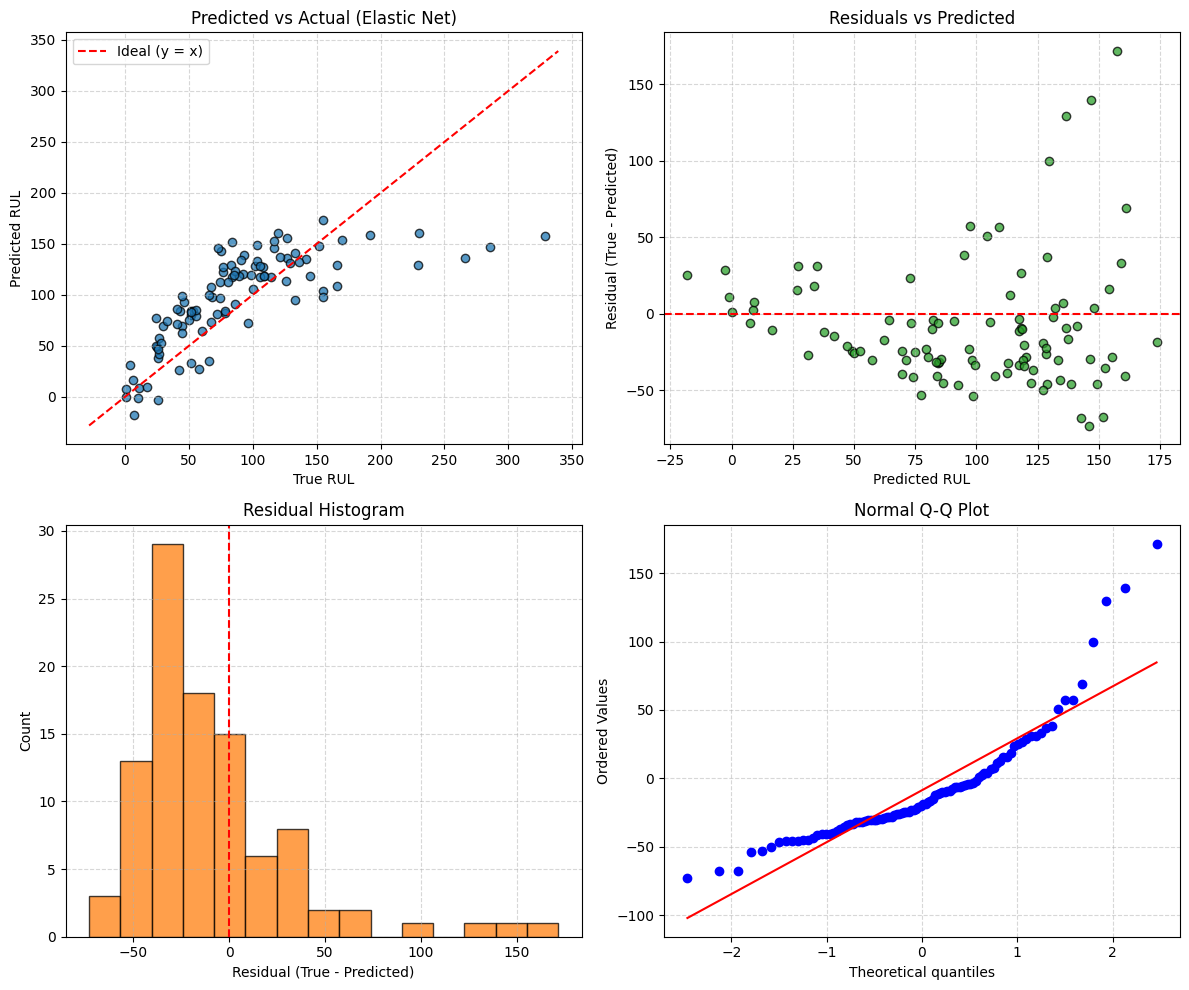

In [7]:
residuals = y_val - en_val_pred

ols_neg = (ols_val_pred < 0).sum()
en_neg = (en_val_pred < 0).sum()
print(f"Negative predictions at 100 validation points — OLS: {ols_neg}, Elastic Net: {en_neg}")

fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# 1. Predicted vs Actual
axs[0, 0].scatter(y_val, en_val_pred, color="#1f77b4", edgecolors="black", alpha=0.75)
diag_min = min(y_val.min(), en_val_pred.min()) - 10
diag_max = max(y_val.max(), en_val_pred.max()) + 10
axs[0, 0].plot([diag_min, diag_max], [diag_min, diag_max], "r--", label="Ideal (y = x)")
axs[0, 0].set_xlabel("True RUL")
axs[0, 0].set_ylabel("Predicted RUL")
axs[0, 0].set_title("Predicted vs Actual (Elastic Net)")
axs[0, 0].legend()
axs[0, 0].grid(True, linestyle="--", alpha=0.5)

# 2. Residuals vs Predicted
axs[0, 1].scatter(en_val_pred, residuals, color="#2ca02c", edgecolors="black", alpha=0.75)
axs[0, 1].axhline(0, color="red", linestyle="--")
axs[0, 1].set_xlabel("Predicted RUL")
axs[0, 1].set_ylabel("Residual (True - Predicted)")
axs[0, 1].set_title("Residuals vs Predicted")
axs[0, 1].grid(True, linestyle="--", alpha=0.5)

# 3. Residual Histogram
axs[1, 0].hist(residuals, bins=15, color="#ff7f0e", edgecolor="black", alpha=0.75)
axs[1, 0].axvline(0, color="red", linestyle="--")
axs[1, 0].set_xlabel("Residual (True - Predicted)")
axs[1, 0].set_ylabel("Count")
axs[1, 0].set_title("Residual Histogram")
axs[1, 0].grid(True, linestyle="--", alpha=0.5)

# 4. Normal Q-Q Plot
stats.probplot(residuals, dist="norm", plot=axs[1, 1])
axs[1, 1].set_title("Normal Q-Q Plot")
axs[1, 1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 7. Coefficients

Inspect the Elastic Net regularized coefficients. The L1 penalty promotes sparsity by zeroing out uninformative or highly redundant features, while the L2 penalty stabilizes correlated features.

Elastic Net zero coefficients: 7 of 57 (removed by L1)
Largest Elastic Net coefficient: cycle (-14.35)


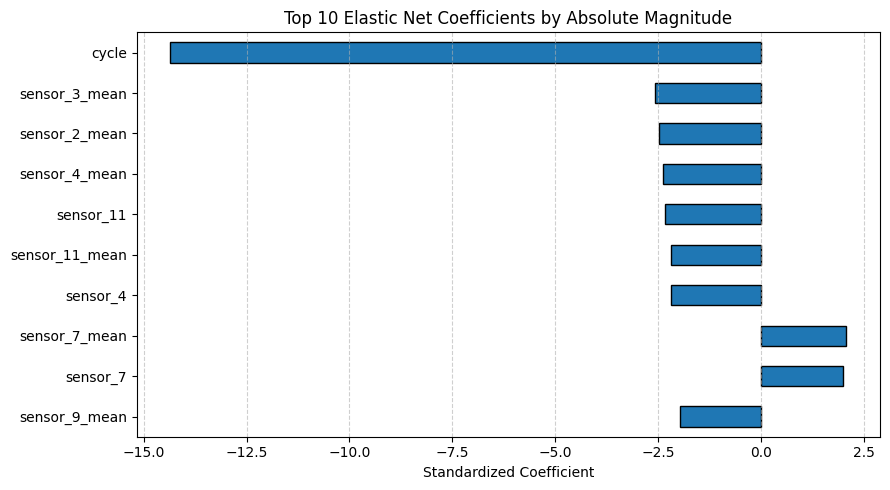

,Coefficient
cycle,-14.3528
sensor_3_mean,-2.5759
sensor_2_mean,-2.4705
sensor_4_mean,-2.3890
sensor_11,-2.3432
sensor_11_mean,-2.1979
sensor_4,-2.1767
sensor_7_mean,2.0711
sensor_7,1.9895
sensor_9_mean,-1.9732


In [8]:
coefs = pd.Series(en[-1].coef_, index=FEATURES)
zero_count = (coefs == 0).sum()
largest_feat = coefs.abs().idxmax()
largest_val = coefs[largest_feat]

print(f"Elastic Net zero coefficients: {zero_count} of {len(coefs)} (removed by L1)")
print(f"Largest Elastic Net coefficient: {largest_feat} ({largest_val:.2f})")

top10 = coefs.loc[coefs.abs().nlargest(10).index]

plt.figure(figsize=(9, 5))
top10.plot(kind="barh", color="#1f77b4", edgecolor="black")
plt.xlabel("Standardized Coefficient")
plt.title("Top 10 Elastic Net Coefficients by Absolute Magnitude")
plt.gca().invert_yaxis()
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

top10.to_frame(name="Coefficient").round(4)

## 8. Save Predictions

Save the validation and test predictions for downstream comparative evaluation:
- `results/val_predictions_linear.csv`: exactly `engine_id, cycle, ols_v1, elastic_net_v2` (100 rows in `val_pts` order).
- `results/test_predictions_linear.csv`: exactly `engine_id, ols_v1, elastic_net_v2` (100 rows in `test_pts` order).

In [9]:
ols_test_pred = ols.predict(test_pts[V1])
en_test_pred = en.predict(test_pts[V2])

print(f"Test predictions for engines 1, 2, 3 (OLS): {np.round(ols_test_pred[:3], 2)}")
print(f"Test predictions for engines 1, 2, 3 (Elastic Net): {np.round(en_test_pred[:3], 2)}")

val_predictions = pd.DataFrame({
    "engine_id": val_pts["engine_id"],
    "cycle": val_pts["cycle"],
    "ols_v1": ols_val_pred,
    "elastic_net_v2": en_val_pred,
})
val_predictions.to_csv("../results/val_predictions_linear.csv", index=False)
print("Saved ../results/val_predictions_linear.csv (shape: %s)" % (val_predictions.shape,))

test_predictions = pd.DataFrame({
    "engine_id": test_pts["engine_id"],
    "ols_v1": ols_test_pred,
    "elastic_net_v2": en_test_pred,
})
test_predictions.to_csv("../results/test_predictions_linear.csv", index=False)
print("Saved ../results/test_predictions_linear.csv (shape: %s)" % (test_predictions.shape,))

Test predictions for engines 1, 2, 3 (OLS): [158.47 121.28  85.13]
Test predictions for engines 1, 2, 3 (Elastic Net): [157.46 135.79  83.91]
Saved ../results/val_predictions_linear.csv (shape: (100, 4))
Saved ../results/test_predictions_linear.csv (shape: (100, 3))
